<a href="https://colab.research.google.com/github/yiskamb/sentiment-app/blob/main/proyek_triase_sentimen_gojek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Otomatisasi Triase Sentimen Ulasan Pengguna Aplikasi Mobile Menggunakan Pendekatan CRISP-DM dan Baseline-First NLP

**Curriculum Developer Intern (Dicoding Indonesia)**   
**Dataset:** `ulasan_com.gojek.app.csv` (100.000 ulasan Google Play Store)  
**Metodologi:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*)  

---

## I. Business Understanding
- **Latar Belakang:** Ulasan masuk di Google Play Store mencapai puluhan ribu per hari. Triase manual lambat dan membuat keluhan kritis (*bug* pembayaran, *crash*) tertunda penanganannya.
- **Tujuan Bisnis:** Membangun sistem klasifikasi biner otomatis untuk menyaring keluhan pelanggan (Negatif) vs apresiasi (Positif) secara seketika (*real-time*).
- **Kriteria Keberhasilan:** Macro F1-Score $\ge$ 85% dengan latensi inferensi rendah.

### 1. Instalasi

In [9]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn joblib

In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_filename = "ulasan_com.gojek.app.csv"
if not os.path.exists(csv_filename):
    from google.colab import files
    print("Silakan unggah file ulasan_com.gojek.app.csv:")
    uploaded = files.upload()

df_raw = pd.read_csv(csv_filename)
print(f"Total baris data mentah: {len(df_raw):,}")
print("\nDistribusi Rating:")
print(df_raw['Rating'].value_counts().sort_index(ascending=False))
df_raw.head(3)

Total baris data mentah: 100,000

Distribusi Rating:
Rating
5    64651
4     5083
3     3534
2     3554
1    23178
Name: count, dtype: int64


,Nama User,Ulasan,Rating,Tanggal,Likes,Versi App
0,Pengguna Google,Mohon agar Gojek menambahkan fitur pembayaran ...,5,2025-12-31 17:12:17,1,5.44.1
1,Pengguna Google,aplikasi kek taik saya pesan gojek prioritas m...,1,2025-12-31 17:09:24,0,NaN
2,Pengguna Google,oke pokonya,5,2025-12-31 16:58:17,0,5.44.1


## III. Data Preparation (Pembersihan Teks & Kamus Slang)
- **Eliminasi Rating 3:** Rating 3 netral/ambigu dieliminasi agar batas klasifikasi tajam.
- **Normalisasi Slang & Negasi:** Mengubah singkatan tidak baku (`apk`, `bgt`, `ga`) menjadi baku dan menjaga kata negasi (`tidak`, `bukan`, `belum`).
- **Balanced Stratified Sampling:** Mengambil 5.000 ulasan Positif dan 5.000 ulasan Negatif.

In [11]:
import re

SLANG_DICTIONARY = {
    "g bsa": "tidak bisa", "ga bisa": "tidak bisa", "gak bisa": "tidak bisa", "gk bisa": "tidak bisa",
    "apk": "aplikasi", "app": "aplikasi", "bgt": "banget", "ga": "tidak", "gak": "tidak", "gk": "tidak",
    "dpt": "dapat", "bodo": "bodoh", "orderan": "pesanan", "driver": "pengemudi", "cs": "layanan pelanggan",
    "eror": "kesalahan", "lemot": "lambat", "lelet": "lambat", "bgus": "bagus", "mantul": "mantap",
    "tp": "tetapi", "klo": "kalau", "sy": "saya", "bsa": "bisa", "oke": "baik"
}

def clean_text(text):
    if not isinstance(text, str) or not text:
        return ""
    text = text.lower()
    text = re.sub(r"https?:\/\/\S+|www\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)

    for slang, formal in SLANG_DICTIONARY.items():
        if " " in slang:
            text = re.sub(r"\b" + re.escape(slang) + r"\b", formal, text)

    tokens = text.split()
    tokens = [SLANG_DICTIONARY.get(t, t) for t in tokens]
    return " ".join(tokens).strip()

# Filter and build binary labels
df_filtered = df_raw.dropna(subset=['Ulasan', 'Rating']).copy()
df_filtered = df_filtered[df_filtered['Rating'] != 3].copy()
df_filtered['sentiment'] = df_filtered['Rating'].apply(lambda r: 0 if r in [1, 2] else 1)
df_filtered['text_clean'] = df_filtered['Ulasan'].apply(clean_text)
df_filtered = df_filtered[df_filtered['text_clean'].str.split().str.len() >= 2].copy()

# Balanced sampling (5000 per class = 10000 total)
df_neg = df_filtered[df_filtered['sentiment'] == 0].sample(n=5000, random_state=42)
df_pos = df_filtered[df_filtered['sentiment'] == 1].sample(n=5000, random_state=42)
df_clean = pd.concat([df_neg, df_pos]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Data bersih seimbang siap latih: {len(df_clean)} sampel.")
df_clean[['Ulasan', 'text_clean', 'sentiment']].head(3)

Data bersih seimbang siap latih: 10000 sampel.


,Ulasan,text_clean,sentiment
0,"Sering dapet promo, Seneng deh!",sering dapet promo seneng deh,1
1,Makin.Jelek,makin jelek,0
2,Semenjak ada fitur scan wajah akun tidak bisa ...,semenjak ada fitur scan wajah akun tidak bisa ...,0


## IV. Modeling: Komparasi 3 Model Baseline (TF-IDF)
- **Train-Test Split:** 80% Latih (8.000) dan 20% Uji (2.000).
- **Feature Extraction:** `TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2)`.
- **Komparasi Model:**
  1. Logistic Regression
  2. Multinomial Naive Bayes
  3. Linear Support Vector Classification (LinearSVC)

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

X = df_clean['text_clean'].values
y = df_clean['sentiment'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(),
    "LinearSVC": LinearSVC(random_state=42, dual="auto")
}

results = []
fitted_pipes = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2)),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    results.append({"Model": name, "Accuracy": acc, "Macro Precision": p, "Macro Recall": r, "Macro F1": f1})
    fitted_pipes[name] = pipe

df_results = pd.DataFrame(results).sort_values(by="Macro F1", ascending=False)
print("=== Hasil Komparasi Model Baseline ===")
display(df_results)

best_model_name = df_results.iloc[0]['Model']
best_pipeline = fitted_pipes[best_model_name]
print(f"\nModel terbaik terpilih: {best_model_name}")

=== Hasil Komparasi Model Baseline ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
2,LinearSVC,0.919,0.919968,0.919,0.918953
0,Logistic Regression,0.916,0.917933,0.916,0.915903
1,Multinomial Naive Bayes,0.905,0.909961,0.905,0.904712



Model terbaik terpilih: LinearSVC


## V. Evaluation: Evaluasi Mendalam & Visualisasi
- Visualisasi *Confusion Matrix*.
- Analisis Koefisien Fitur (*Feature Importance*).
- *Error Analysis* pada sampel uji.

=== Classification Report ===
                     precision    recall  f1-score   support

  Negatif (Keluhan)       0.90      0.94      0.92      1000
Positif (Apresiasi)       0.94      0.90      0.92      1000

           accuracy                           0.92      2000
          macro avg       0.92      0.92      0.92      2000
       weighted avg       0.92      0.92      0.92      2000



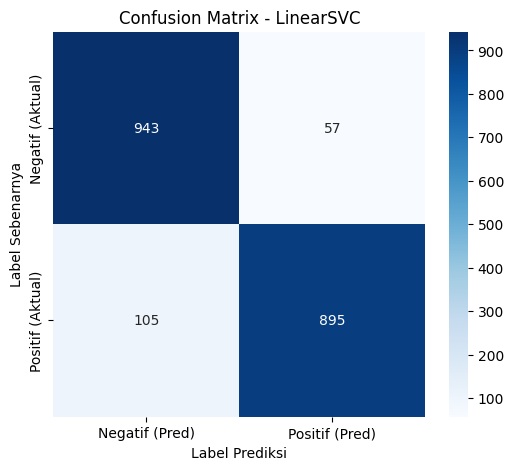


Top 10 Kata Paling Positif: ['mantap' 'baik' 'bagus' 'cepat' 'keren' 'mudah' 'bikin susah' 'membantu'
 'nya bagus' 'memudahkan']
Top 10 Kata Paling Negatif: ['buruk' 'jelek' 'tidak bagus' 'tidak' 'malah' 'parah' 'iklan' 'pengemudi'
 'pelit' 'tidak ramah']


In [13]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_best = best_pipeline.predict(X_test)
print("=== Classification Report ===")
print(classification_report(y_test, y_pred_best, target_names=["Negatif (Keluhan)", "Positif (Apresiasi)"]))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negatif (Pred)", "Positif (Pred)"],
            yticklabels=["Negatif (Aktual)", "Positif (Aktual)"])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.ylabel("Label Sebenarnya")
plt.xlabel("Label Prediksi")
plt.show()

# Feature importance (coefficients)
if hasattr(best_pipeline.named_steps['clf'], 'coef_'):
    coef = best_pipeline.named_steps['clf'].coef_[0]
    feature_names = np.array(best_pipeline.named_steps['tfidf'].get_feature_names_out())

    top_pos = feature_names[np.argsort(coef)[-10:][::-1]]
    top_neg = feature_names[np.argsort(coef)[:10]]

    print("\nTop 10 Kata Paling Positif:", top_pos)
    print("Top 10 Kata Paling Negatif:", top_neg)

## VI. Deployment & Uji Coba Interaktif
Pengujian langsung model pada kalimat baru (inferensi seketika).

In [14]:
import joblib

# Save the pipeline artifact
os.makedirs("models", exist_ok=True)
joblib.dump(best_pipeline, "models/sentiment_pipeline.joblib")
print("Model pipeline tersimpan di models/sentiment_pipeline.joblib")

# Interactive inference function
def prediksi_ulasan(teks):
    teks_bersih = clean_text(teks)
    pred = best_pipeline.predict([teks_bersih])[0]
    label = "POSITIF" if pred == 1 else "NEGATIF (Keluhan / Bug)"
    skor = best_pipeline.decision_function([teks_bersih])[0]
    print(f"Teks Asli   : {teks}")
    print(f"Teks Bersih : {teks_bersih}")
    print(f"Prediksi    : {label} (Skor keputusan: {skor:.3f}, di atas 0 = positif)\n")

# Test with real review examples
prediksi_ulasan("Aplikasi mantap banget, sangat membantu saat cari ojek buru-buru!")
prediksi_ulasan("Kecewa banget, saldo gopay kepotong tapi pesanan malah gagal terus!")
prediksi_ulasan("Tolong perbaiki bug saat pembayaran sering eror dan keluar sendiri.")

Model pipeline tersimpan di models/sentiment_pipeline.joblib
Teks Asli   : Aplikasi mantap banget, sangat membantu saat cari ojek buru-buru!
Teks Bersih : aplikasi mantap banget sangat membantu saat cari ojek buru buru
Prediksi    : POSITIF (Skor keputusan: 0.570, di atas 0 = positif)

Teks Asli   : Kecewa banget, saldo gopay kepotong tapi pesanan malah gagal terus!
Teks Bersih : kecewa banget saldo gopay kepotong tapi pesanan malah gagal terus
Prediksi    : NEGATIF (Keluhan / Bug) (Skor keputusan: -1.240, di atas 0 = positif)

Teks Asli   : Tolong perbaiki bug saat pembayaran sering eror dan keluar sendiri.
Teks Bersih : tolong perbaiki bug saat pembayaran sering kesalahan dan keluar sendiri
Prediksi    : NEGATIF (Keluhan / Bug) (Skor keputusan: -0.793, di atas 0 = positif)

